# Elliptical Trajectory Conditions (Smaller Scale) and CNN Inference

We reduced ellipse perimeter from 160 cm to **32 cm**, retained the **2.5 s period**, and kept the same relative velocity modulation and slowing locations. Average speed is therefore 12.8 cm/s. This is a scaled exploratory test of the idea, not an exact replication of the human experiment.

Sources: Viviani, Baud-Bovy & Redolfi (1997), Experiment 1, Table 1 and Figure 3, [primary paper](../../Elliptical%20Trajectories/Perceiving_and_Tracking_Kinesthetic_Stimuli_Furthe%20(1).pdf). Published pretrained weights: [Zenodo 15111808](https://zenodo.org/records/15111808). The older full-size ensemble notebook is archived under `notebooks/archive/` and is not run here.


## 1. Elliptical trajectories being tested

Positive signed eccentricity means a horizontal ellipse; negative means vertical. Seven shapes × three velocity conditions give **21 trajectories**. A has constant tangential speed. B slows at the left/right extremes. C slows at the top/bottom. Spatial scaling changes absolute speeds but preserves the phase and the relative speed pattern exactly; this invariant is checked in the tests.

Paths are centered at the original shoulder/elbow rest posture (20°, 40°, 25°, 85°) in a frontoparallel X–Z plane. The circle radius is 5.09 cm; the most elongated ellipse has semiaxes about 7.54 and 2.35 cm. Three cycles are generated; shape readout uses the final cycle.

The reference Lissajous eccentricity remains .9, giving a speed ratio 2.294. The paper's stated numerical ratio 3.205 corresponds to .95; changing that parameter is a separate sensitivity test.


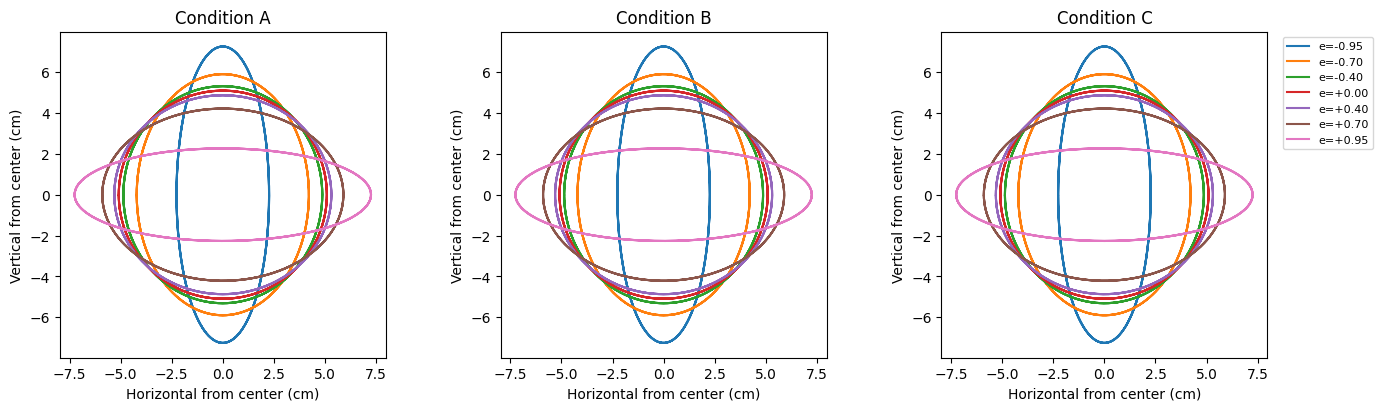

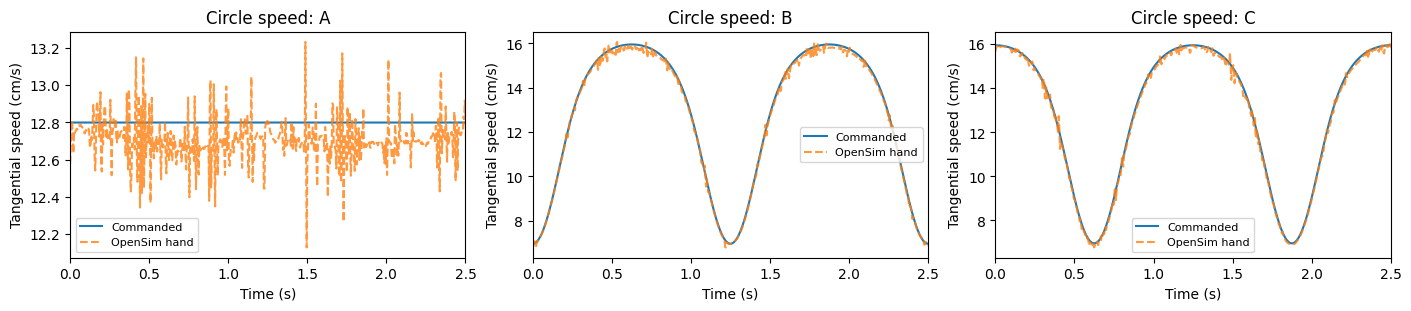

In [1]:
from pathlib import Path
import os, sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'run_pipeline.py').exists())
CONFIG_PATH=ROOT/'experiments/viviani_small.yaml'
CONFIG=yaml.safe_load(CONFIG_PATH.read_text())
OUT=ROOT/'outputs'/CONFIG['experiment'];OUT.mkdir(exist_ok=True)
OPEN_SIM_PYTHON=ROOT/'.venv-opensim/bin/python'
INFERENCE_PYTHON=ROOT/'.venv-mujoco/bin/python'
CHECKPOINT=ROOT/CONFIG['proprioception']['model_path']
RUN_BIOMECHANICS=False  # True reruns the original path → IK → motion → muscle → spindle stages.
RUN_INFERENCE=False  # True reruns the original inference stage, with just the configured CNN.
CIRCLE_RATIO_TOLERANCE=1.05
CLASSES=['true circle','horizontal ellipse','vertical ellipse']
PERIOD=CONFIG['path']['ellipse']['period_s'];FS=CONFIG['path']['sample_rate_hz']
plt.rcParams.update({'font.size':10,'figure.figsize':(10,4)})
CONFIG_SIGNATURE=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode()).hexdigest()

def run_stage(stage,python):
    (OUT/'.matplotlib').mkdir(exist_ok=True)
    command=[str(python),'-c',f"from run_pipeline import Pipeline; Pipeline({str(CONFIG_PATH)!r}).run_stage({stage!r})"]
    env=dict(os.environ,MPLBACKEND='Agg',MPLCONFIGDIR=str(OUT/'.matplotlib'))
    log=OUT/(stage+'.log')
    with log.open('w') as stream:
        result=subprocess.run(command,cwd=ROOT,env=env,stdout=stream,stderr=subprocess.STDOUT)
    if result.returncode:raise RuntimeError(f'{stage} failed: {log}\n'+log.read_text()[-2000:])
    print('Completed',stage)

if RUN_BIOMECHANICS:
    for stage in ['path','inverse-kinematics','motion','muscle-lengths','muscle-signals']:run_stage(stage,OPEN_SIM_PYTHON)
stimuli=pd.read_csv(OUT/'stimuli.csv')
manifest=yaml.safe_load((OUT/'manifest.yaml').read_text());entries={r['id']:r for r in manifest['trajectories']}
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    for row in stimuli[stimuli.condition==condition].itertuples():
        d=np.load(OUT/entries[row.id]['desired_path']);center=d['center_xyz'];xy=d['xyz'][:,[0,2]]-center[[0,2]]
        ax.plot(*xy.T,label=f'e={row.e:+.2f}')
    ax.set(title=f'Condition {condition}',xlabel='Horizontal from center (cm)',ylabel='Vertical from center (cm)',aspect='equal')
axes[-1].legend(fontsize=8,bbox_to_anchor=(1.03,1));plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,3),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    ident=stimuli[(stimuli.condition==condition)&(stimuli.e==0)].id.iloc[0]
    d=np.load(OUT/entries[ident]['desired_path']);speed=np.linalg.norm(np.gradient(d['xyz'],1/FS,axis=0),axis=1)
    ax.plot(d['times'],speed,label='Commanded')
    physical=np.load(OUT/entries[ident]['muscle_data'])
    delivered_speed=np.linalg.norm(np.gradient(physical['wrist_xyz_reference_world'],1/FS,axis=0),axis=1)
    ax.plot(physical['times'],delivered_speed,'--',label='OpenSim hand',alpha=.8)
    ax.set(xlim=(0,PERIOD),title=f'Circle speed: {condition}',xlabel='Time (s)',ylabel='Tangential speed (cm/s)');ax.legend(fontsize=8)
plt.show()


## 2. Check muscle paths, then calculate spindle firing rates

**Original-pipeline test:** a 32 cm circle at the original rest posture produced fibres around 19–208 mm, without the earlier metre-scale failures. This baseline is retained in `outputs/viviani_small_probe/`.

**First failed large-path sample:** `A_m0_40`, frame 0, teres minor (`TMIN`). Shoulder elevation was about 139.2°. Its saved fibre length was 2,217 mm; a fresh OpenSim model reproduced that value. The full muscle–tendon path was 2,631 mm. Inspection of `GeometryPath.getCurrentPath()` showed generated wrapping points far outside the shoulder region. This confirms a failed muscle route at that posture; it does not justify changing a wrapping surface globally.

**Correction:** use smaller paths around the existing rest posture and align forearm rotation between IK and muscle extraction. The original IK brace was −30° while the training-compatible extractor used the model's 0° default. Both now use 0°, preserving the original four-coordinate muscle-input convention. The original OpenSim IK backend is retained; the original .001 posture regularization is retained to keep muscle signals smooth. No wrapping surfaces were disabled and no fibre lengths were clipped or replaced.

The graphs below inspect the failed and successful muscle routes and verify all 21 new conditions. These checks screen for simulation failures; they are not a full physiological validation. The spindle calculation is the existing 25-muscle, 5 Ia + 5 II pipeline with coefficient seed 0.

The hand-tracking screen is 0.2 cm (2 mm); delivered shape labels are also checked against commanded labels. A trial with reduced posture regularization improved marker error but caused joint/velocity jumps, so that setting was rejected before final inference.

The 3D diagnostic connects the path points returned by OpenSim; it does not render the curved wrapping arcs. Reported muscle–tendon lengths come directly from OpenSim.


,id,max_hand_error_cm,min_fiber_mm,max_fiber_mm,min_normalized_length,max_normalized_length,peak_velocity_mm_s,min_rate_hz,max_rate_hz,delivered_class,delivered_ratio,passed
0,A_m0_95,0.064415,18.495415,209.166183,0.592925,1.377610,104.456169,0.0,25.799723,vertical ellipse,0.310727,True
1,B_m0_95,0.064682,18.495838,209.151657,0.592923,1.377662,106.234123,0.0,26.102213,vertical ellipse,0.310869,True
2,C_m0_95,0.064741,18.495852,209.507996,0.592735,1.377599,108.198845,0.0,25.548328,vertical ellipse,0.310804,True
3,A_m0_70,0.078459,18.793097,208.552902,0.594639,1.373383,94.052116,0.0,26.570004,vertical ellipse,0.710647,True
4,B_m0_70,0.078342,18.792952,208.581161,0.594557,1.373383,94.639885,0.0,26.718117,vertical ellipse,0.710828,True
5,C_m0_70,0.078416,18.792816,208.694733,0.594621,1.373383,93.550407,0.0,26.727894,vertical ellipse,0.710616,True
6,A_m0_40,0.091722,18.917097,208.279556,0.595322,1.372274,91.431877,0.0,26.975775,vertical ellipse,0.912010,True
7,B_m0_40,0.089937,18.917091,208.073853,0.595414,1.372274,91.054680,0.0,27.057571,vertical ellipse,0.912039,True
8,C_m0_40,0.089581,18.917154,208.379379,0.595414,1.372274,90.635368,0.0,27.065676,vertical ellipse,0.911843,True
9,A_p0_00,0.094227,18.962580,208.174088,0.595704,1.371863,91.054680,0.0,26.938782,true circle,0.994956,True


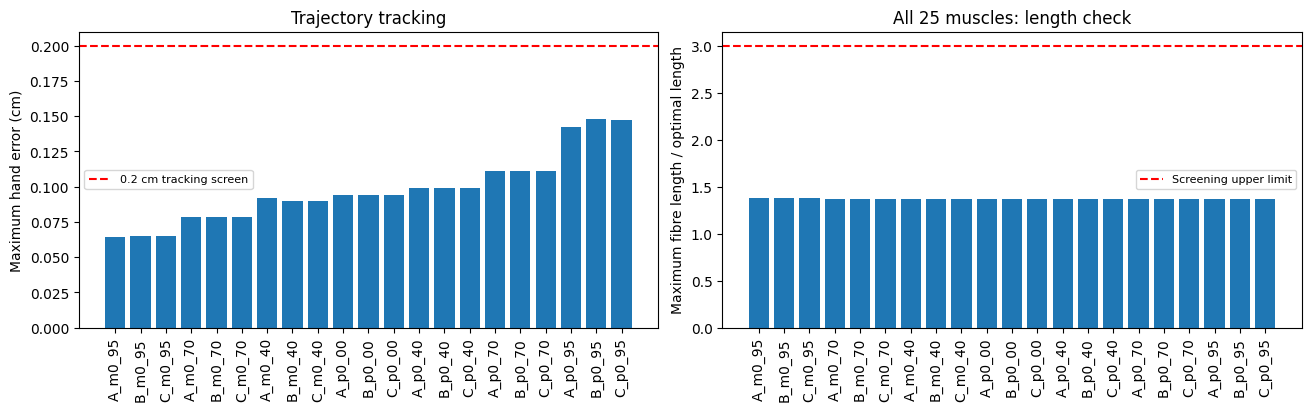

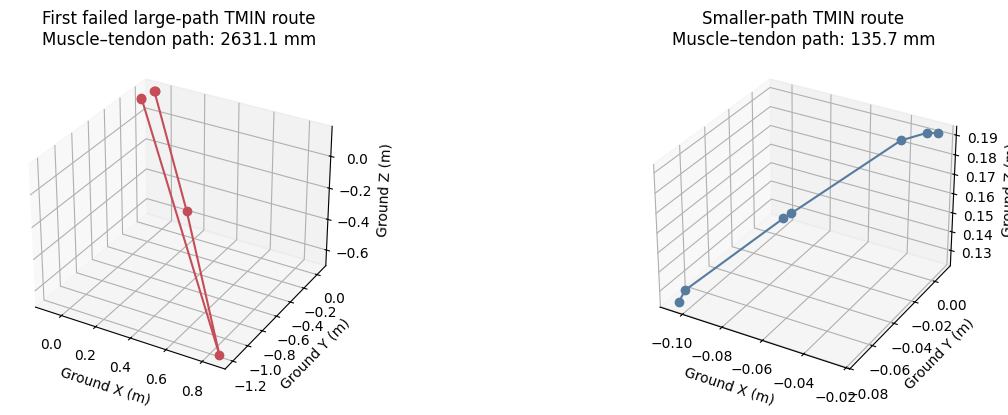

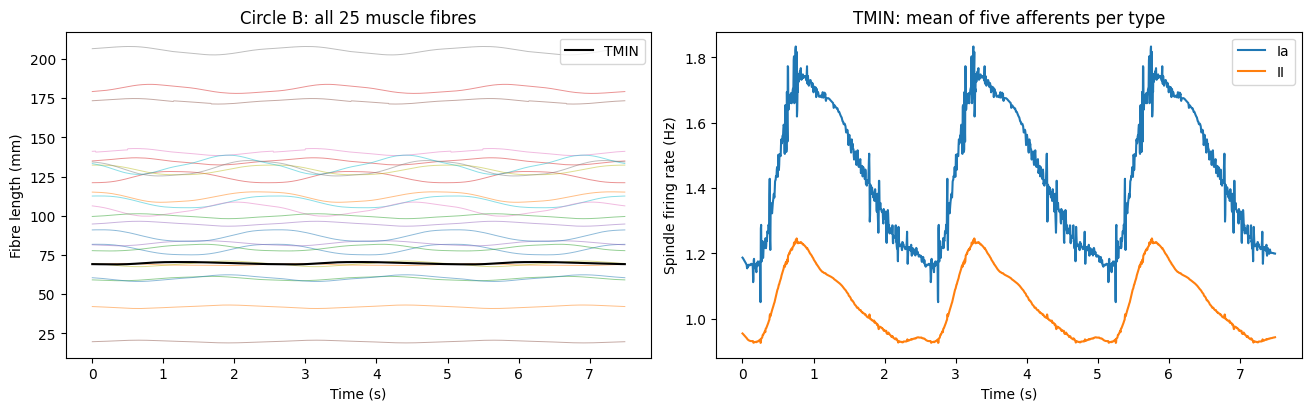

All 21 stimuli pass the simulation checks.


In [2]:
optimal=np.asarray(yaml.safe_load((ROOT/'extract_data/configs/train_test_data_spindles_extended.yaml').read_text())['optimal_lengths'])
quality=[]
for row in stimuli.itertuples():
    item=entries[row.id];desired=np.load(OUT/item['desired_path']);muscle=np.load(OUT/item['muscle_data']);spindle=np.load(OUT/item['spindle_data'])
    lengths=muscle['fiber_lengths'];ratio=lengths/optimal[None,:]
    error=np.linalg.norm(muscle['wrist_xyz_reference_world']-desired['xyz'],axis=1)
    extent=np.ptp(muscle['wrist_xyz_reference_world'][-600:,[0,2]],axis=0)
    delivered_ratio=extent[0]/extent[1]
    delivered_class=CLASSES[0] if 1/CIRCLE_RATIO_TOLERANCE<=delivered_ratio<=CIRCLE_RATIO_TOLERANCE else CLASSES[1 if delivered_ratio>1 else 2]
    peak_velocity=np.abs(np.gradient(lengths,1/FS,axis=0)).max()
    rates=spindle['firing_rates']
    passed=bool(np.isfinite(lengths).all() and np.isfinite(rates).all() and ratio.min()>.1 and ratio.max()<3 and error.max()<.2 and peak_velocity<500 and delivered_class==row.correct)
    quality.append(dict(id=row.id,max_hand_error_cm=error.max(),min_fiber_mm=lengths.min(),max_fiber_mm=lengths.max(),min_normalized_length=ratio.min(),max_normalized_length=ratio.max(),peak_velocity_mm_s=peak_velocity,min_rate_hz=rates.min(),max_rate_hz=rates.max(),delivered_class=delivered_class,delivered_ratio=delivered_ratio,passed=passed))
quality=pd.DataFrame(quality);quality.to_csv(OUT/'quality.csv',index=False)
display(quality)
assert quality.passed.all(), 'A simulation check failed; inspect the inputs before running the CNN.'
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].bar(quality.id,quality.max_hand_error_cm);axes[0].axhline(.2,c='red',ls='--',label='0.2 cm tracking screen');axes[0].tick_params(axis='x',rotation=90);axes[0].set(ylabel='Maximum hand error (cm)',title='Trajectory tracking');axes[0].legend(fontsize=8)
axes[1].bar(quality.id,quality.max_normalized_length);axes[1].axhline(3,c='red',ls='--',label='Screening upper limit');axes[1].tick_params(axis='x',rotation=90);axes[1].set(ylabel='Maximum fibre length / optimal length',title='All 25 muscles: length check');axes[1].legend(fontsize=8);plt.show()
audit=json.loads((OUT/'muscle_path_audit.json').read_text())
fig=plt.figure(figsize=(13,4.5));fig.subplots_adjust(left=.03,right=.88,bottom=.10,top=.85,wspace=.30)
for index,key,title in [(1,'failed','First failed large-path TMIN route'),(2,'small','Smaller-path TMIN route')]:
    ax=fig.add_subplot(1,2,index,projection='3d');a=audit[key];xyz=np.array(a['path_points_ground_m'])
    ax.plot(*xyz.T,'o-',color='#c44d58' if key=='failed' else '#557b9e')
    ax.set(title=f"{title}\nMuscle–tendon path: {a['musculotendon_length_mm']:.1f} mm",xlabel='Ground X (m)',ylabel='Ground Y (m)',zlabel='Ground Z (m)')
plt.show()
ident=stimuli[(stimuli.condition=='B')&(stimuli.e==0)].id.iloc[0]
m=np.load(OUT/entries[ident]['muscle_data']);s=np.load(OUT/entries[ident]['spindle_data'])
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].plot(m['times'],m['fiber_lengths'],alpha=.5,lw=.7)
i=list(m['muscle_names']).index('TMIN');axes[0].plot(m['times'],m['fiber_lengths'][:,i],c='black',lw=1.5,label='TMIN')
axes[0].set(xlabel='Time (s)',ylabel='Fibre length (mm)',title='Circle B: all 25 muscle fibres');axes[0].legend()
for start,label in [(0,'Ia'),(5,'II')]:
    axes[1].plot(s['times'],s['firing_rates'][0,start:start+5,i,:].mean(axis=0),label=label)
axes[1].set(xlabel='Time (s)',ylabel='Spindle firing rate (Hz)',title='TMIN: mean of five afferents per type');axes[1].legend();plt.show()
print('All',len(quality),'stimuli pass the simulation checks.')


## 3. Single-CNN reconstruction and shape classification

This runs `process/centeroutinference.py`, the inference stage already used in your codebase, with the configured `0_9` checkpoint. Its existing normalization and `replicate` temporal padding are preserved. The original 240 Hz timebase is retained. No other checkpoint is loaded.

The CNN outputs wrist XYZ and four joint angles. To read shape in the physical frontoparallel plane, its four predicted joint angles are placed in the same OpenSim model. Shape is measured from horizontal/vertical extent in the final cycle: a ratio within [1/1.05, 1.05] is labelled circle, greater is horizontal, smaller is vertical. This is a fixed geometric readout of the pretrained reconstruction, not a newly trained classification head or calibrated probability.


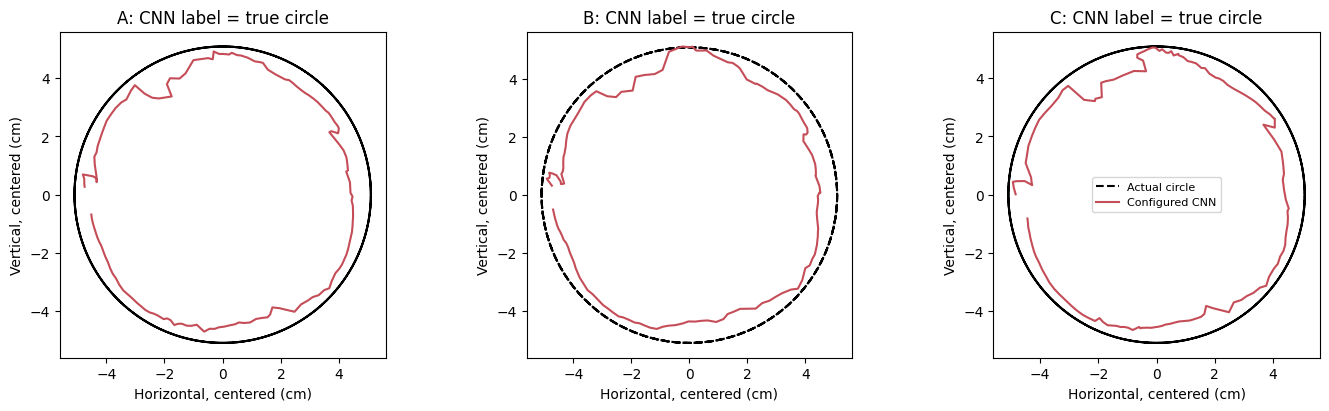

,id,correct,predicted,ratio,predicted_e,joint_out_of_bounds_fraction
0,A_m0_95,vertical ellipse,vertical ellipse,0.273698,-0.961816,0.0
1,B_m0_95,vertical ellipse,vertical ellipse,0.293808,-0.955864,0.0
2,C_m0_95,vertical ellipse,vertical ellipse,0.271034,-0.962570,0.0
3,A_m0_70,vertical ellipse,vertical ellipse,0.657757,-0.753230,0.0
4,B_m0_70,vertical ellipse,vertical ellipse,0.660880,-0.750492,0.0
5,C_m0_70,vertical ellipse,vertical ellipse,0.684435,-0.729074,0.0
6,A_m0_40,vertical ellipse,vertical ellipse,0.864145,-0.503243,0.0
7,B_m0_40,vertical ellipse,vertical ellipse,0.873232,-0.487304,0.0
8,C_m0_40,vertical ellipse,vertical ellipse,0.869016,-0.494783,0.0
9,A_p0_00,true circle,true circle,0.964499,-0.264087,0.0


Checkpoint: trained_models/experiment_causal_flag-pcr_optimized_linear_extended_5_5_letter_reconstruction_joints/spatiotemporal_4_8-8-32-64_7171_0_9
Models used: 1 | predictions: 21
Fraction of decoded frames outside joint limits: 0.0


In [3]:
if RUN_INFERENCE:
    run_stage('inference',INFERENCE_PYTHON)
    inventory=[]
    for row in stimuli.itertuples():
        item=yaml.safe_load((OUT/'manifest.yaml').read_text())
        entry=next(r for r in item['trajectories'] if r['id']==row.id)
        inventory.append(dict(id=row.id,condition=row.condition,e=row.e,coefficient_seed=CONFIG['proprioception']['coefficient_seed'],training_seed=CONFIG['proprioception']['training_seed'],predictions=entry['raw_predictions']))
    (OUT/'batch').mkdir(exist_ok=True)
    pd.DataFrame(inventory).to_csv(OUT/'batch/inventory.csv',index=False)
    (OUT/'generation.json').write_text(json.dumps(dict(signature=CONFIG_SIGNATURE)))
    with (OUT/'readout.log').open('w') as log:
        subprocess.run([str(OPEN_SIM_PYTHON),'process/ellipse_readout.py','--output',str(OUT),'--tolerance',str(CIRCLE_RATIO_TOLERANCE)],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
    provenance=dict(n_models=1,model_path=str(CHECKPOINT.relative_to(ROOT)),checkpoint_sha256=hashlib.sha256((CHECKPOINT/'model.ckpt').read_bytes()).hexdigest(),config_signature=CONFIG_SIGNATURE,temporal_padding=CONFIG['proprioception']['temporal_padding_mode'])
    (OUT/'single_model_provenance.json').write_text(json.dumps(provenance,indent=2))
provenance=json.loads((OUT/'single_model_provenance.json').read_text())
assert provenance['n_models']==1 and provenance['config_signature']==CONFIG_SIGNATURE
assert provenance['checkpoint_sha256']==hashlib.sha256((CHECKPOINT/'model.ckpt').read_bytes()).hexdigest()
assert json.loads((OUT/'batch/readout.json').read_text())['tolerance']==CIRCLE_RATIO_TOLERANCE
predictions=pd.read_csv(OUT/'batch/shape_predictions.csv')
assert len(predictions)==len(stimuli) and len(predictions[['coefficient_seed','training_seed']].drop_duplicates())==1
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    row=predictions[(predictions.condition==condition)&(predictions.e==0)].iloc[0]
    xyz=np.load(OUT/row.physical_prediction)['xyz'];xy=xyz[:,[0,2]];xy-=xy.mean(axis=0)
    desired=np.load(OUT/entries[row.id]['desired_path']);truth=desired['xyz'][:,[0,2]]-desired['center_xyz'][[0,2]]
    ax.plot(*truth.T,'k--',label='Actual circle');ax.plot(*xy.T,c='#c44d58',label='Configured CNN')
    ax.set(title=f'{condition}: CNN label = {row.predicted}',xlabel='Horizontal, centered (cm)',ylabel='Vertical, centered (cm)',aspect='equal')
axes[-1].legend(fontsize=8);plt.show()
display(predictions[['id','correct','predicted','ratio','predicted_e','joint_out_of_bounds_fraction']])
print('Checkpoint:',provenance['model_path'])
print('Models used:',provenance['n_models'],'| predictions:',len(predictions))
print('Fraction of decoded frames outside joint limits:',predictions.joint_out_of_bounds_fraction.mean())


## 4. CNN output versus the correct geometric answer

Each trajectory contributes one prediction from the single configured CNN. The confusion matrix contains 21 entries, not an ensemble or independent human trials. The continuous curves preserve shape information lost by the three labels. Each physical ellipse should have the same correct label in A, B and C.


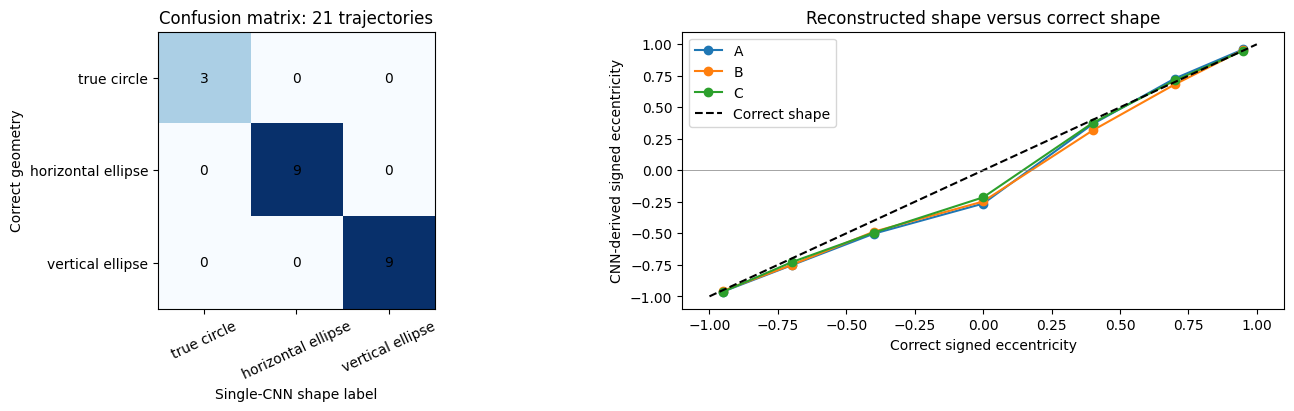

,fraction_correct
condition,
A,1.0
B,1.0
C,1.0


Overall screening accuracy: 1.0


In [4]:
matrix=pd.crosstab(predictions.correct,predictions.predicted).reindex(index=CLASSES,columns=CLASSES,fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].imshow(matrix,cmap='Blues');axes[0].set(xticks=range(3),yticks=range(3),xticklabels=CLASSES,yticklabels=CLASSES,xlabel='Single-CNN shape label',ylabel='Correct geometry',title='Confusion matrix: 21 trajectories');axes[0].tick_params(axis='x',rotation=25)
for i in range(3):
    for j in range(3):axes[0].text(j,i,str(matrix.iloc[i,j]),ha='center',va='center')
for condition,g in predictions.groupby('condition'):
    g=g.sort_values('e');axes[1].plot(g.e,g.predicted_e,'o-',label=condition)
axes[1].plot([-1,1],[-1,1],'k--',label='Correct shape');axes[1].axhline(0,c='gray',lw=.5)
axes[1].set(xlabel='Correct signed eccentricity',ylabel='CNN-derived signed eccentricity',title='Reconstructed shape versus correct shape');axes[1].legend();plt.show()
accuracy=predictions.assign(is_correct=predictions.correct==predictions.predicted).groupby('condition').is_correct.mean()
display(accuracy.rename('fraction_correct').to_frame())
print('Overall screening accuracy:',(predictions.correct==predictions.predicted).mean())


## 5. Single CNN versus the human data

Humans made a flat/tall choice, so a three-class accuracy is not directly comparable. We compare physical eccentricity at subjective circularity (PSE). The human means are A −.091, B −.267, C .026 (Table 1, n=20). A CNN PSE is the unique zero crossing of its decoded signed eccentricity, linearly interpolated from the screening grid. Missing or multiple crossings are reported rather than fitted away.

This is a **scaled exploratory comparison**: the stimuli are smaller and slower, and the simulated posture differs from the human setup. Human JNDs (.095, .148, .114; Figure 3) are reference values; one deterministic CNN does not provide a human-style psychometric JND. There are no model-ensemble averages or error bars. Model predictions can disagree with humans even when spindle inputs pass the simulation checks.


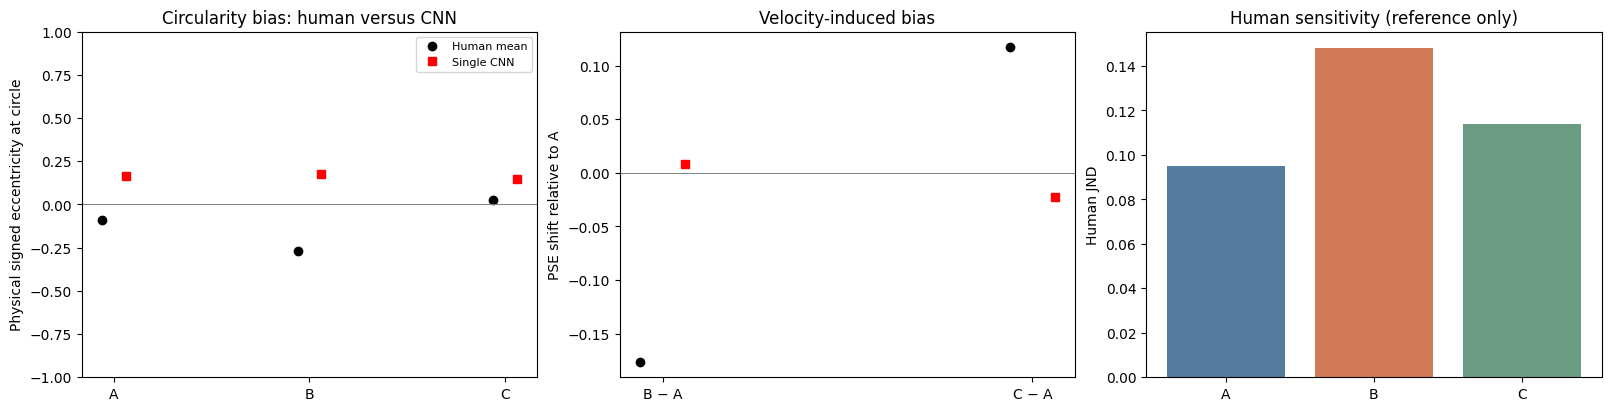

,condition,human_pse,human_jnd,cnn_pse,cnn_minus_human
0,A,-0.091,0.095,0.167537,0.258537
1,B,-0.267,0.148,0.175550,0.442550
2,C,0.026,0.114,0.145345,0.119345


Averaging across models: none. One prediction per trajectory from the configured CNN.
Missing/nonunique CNN PSEs: 0


In [5]:
human=pd.DataFrame(dict(condition=list('ABC'),human_pse=[-.091,-.267,.026],human_jnd=[.095,.148,.114]))
def zero_crossing(x,y):
    x,y=np.asarray(x),np.asarray(y)
    if not np.isfinite(y).all():return np.nan
    order=np.argsort(x);x,y=x[order],y[order];roots=list(x[np.abs(y)<1e-10])
    for i in range(len(x)-1):
        if y[i]*y[i+1]<0:roots.append(x[i]-y[i]*(x[i+1]-x[i])/(y[i+1]-y[i]))
    return roots[0] if len(roots)==1 else np.nan
pse={c:zero_crossing(g.e,g.predicted_e) for c,g in predictions.groupby('condition')}
comparison=human.copy();comparison['cnn_pse']=comparison.condition.map(pse)
comparison['cnn_minus_human']=comparison.cnn_pse-comparison.human_pse
comparison.to_csv(OUT/'human_model_comparison.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(16,4),layout='constrained');x=np.arange(3)
axes[0].plot(x-.06,comparison.human_pse,'ko',label='Human mean');axes[0].plot(x+.06,comparison.cnn_pse,'rs',label='Single CNN')
for i,value in enumerate(comparison.cnn_pse):
    if not np.isfinite(value):axes[0].text(i,.90,'No unique\nCNN crossing',ha='center',fontsize=8)
axes[0].axhline(0,c='gray',lw=.7);axes[0].set(xticks=x,xticklabels=list('ABC'),ylim=(-1,1),ylabel='Physical signed eccentricity at circle',title='Circularity bias: human versus CNN');axes[0].legend(fontsize=8)
for i,c in enumerate('BC'):
    human_shift=float(comparison.set_index('condition').human_pse[c]-comparison.set_index('condition').human_pse.A)
    model_shift=pse[c]-pse['A']
    axes[1].plot(i-.06,human_shift,'ko');axes[1].plot(i+.06,model_shift,'rs')
axes[1].axhline(0,c='gray',lw=.7);axes[1].set(xticks=[0,1],xticklabels=['B − A','C − A'],ylabel='PSE shift relative to A',title='Velocity-induced bias')
axes[2].bar(x,comparison.human_jnd,color=['#557b9e','#cf7957','#6b9b82']);axes[2].set(xticks=x,xticklabels=list('ABC'),ylabel='Human JND',title='Human sensitivity (reference only)');plt.show()
display(comparison)
print('Averaging across models: none. One prediction per trajectory from the configured CNN.')
print('Missing/nonunique CNN PSEs:',comparison.cnn_pse.isna().sum())


**Reproducibility.** Outputs and checks are in `outputs/viviani_small/`. The active experiment is `experiments/viviani_small.yaml`; original and large-path diagnostic outputs are retained separately. Checkpoint and configuration hashes are recorded in `single_model_provenance.json`. To regenerate, set both run flags to `True` and run cells in order. Existing notebooks `run_pipeline.ipynb` and `mujoco_spindle_pipeline.ipynb` are not overwritten by this notebook.

**Limits.** Passing marker, fibre-length and velocity screens removes the specific failures seen previously; it does not prove that synthetic firing rates equal human afferent recordings. The scale, speed, posture, spindle approximation and fixed geometric readout all limit conclusions about the human illusion. No human data were used to train or tune the CNN.
